# AP 155 Lab Exercise
---
## Exercise 12: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Agbay, Tristan Michael
- _Student No._: 2024-00281
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Initial spin configuration](figures/fig1_initial.png)

**Figure 1. Initial spin configuration.** Random $20\times20$ lattice of $\pm1$ spins (seed 21), orange/up-arrow for $S=+1$ and blue/down-arrow for $S=-1$. This same lattice is the starting point of both 10,000-sweep runs in Figures 2-5. It has $m=-0.015$ and $H=0$, with $J=k_B=1$ and $B=0$.

![Final configuration at T = 1](figures/fig2_final_low.png)

![Final configuration at T = 3](figures/fig2_final_high.png)

**Figures 2-3. Spin configuration after 10,000 sweeps ($4\times10^6$ attempted flips), $B=0$.** Both start from Figure 1. Top: $T=1$, below $T_C\approx2.269$, where the whole lattice ends up aligned ($m=-1$, $H=-800$). Bottom: $T=3$, above $T_C$, where the lattice stays a mix of small up and down patches ($m=+0.045$, $H=-312$).

![m and H vs sweeps for the 10,000-sweep run at T = 1](figures/fig3_long_low.png)

![m and H vs sweeps for the 10,000-sweep run at T = 3](figures/fig3_long_high.png)

**Figures 4-5. Magnetization per spin and total energy over the full 10,000 sweeps, $B=0$.** These are the same two runs that produced Figures 2-3, so they show how each one reached its final state. Top: $T=1$, which drops to the ground state within about 100 sweeps and then stays there, with small spikes from rare single-spin flips. Bottom: $T=3$, which never settles and keeps fluctuating around $m=0$ and $H\approx-328$. The dashed line is $H=-2JN^2=-800$.

![m and H vs sweeps at T = 1, B = 0](figures/fig4_mE_low.png)

![m and H vs sweeps at T = 3, B = 0](figures/fig4_mE_high.png)

**Figures 6-7. Magnetization per spin and total energy vs Monte Carlo sweeps, $B=0$, four initial lattices.** Seeds 21-24, 2,500 sweeps each ($10^6$ attempted flips). Top: $T=1$, where lattices 21 and 22 settle at $m=-1$ and lattices 23 and 24 at $m=+1$. Bottom: $T=3$, where $m$ just fluctuates around 0. The dashed line is the ground state $-800$.

![m and H vs sweeps at T = 1, B = 0.5](figures/fig5_mE_B_low.png)

![m and H vs sweeps at T = 3, B = 0.5](figures/fig5_mE_B_high.png)

**Figures 8-9. Magnetization per spin and total energy vs Monte Carlo sweeps, $B=0.5$.** Same four initial lattices and same run length as Figures 6-7. Top: $T=1$, all four runs go to $m=+1$. Bottom: $T=3$, all four runs sit near $m=+0.77$. The dashed line is the new ground state $-2JN^2-BN^2=-1000$.

### Report discussion

**Explain the figures.**

Figure 1 is a random lattice, so up and down spins are mixed with no pattern. After 10,000 sweeps the two temperatures look completely different (Figures 2-3). At $T=1$ every spin points the same way, while at $T=3$ the lattice is still patchy, with clusters only a few sites wide. Figures 4-5 show how those two runs got there: the $T=1$ run reaches the ground state within about 100 sweeps and stays, while the $T=3$ run never settles. Figures 6-7 repeat this with four starting lattices, and the four $T=1$ runs split two to $m=-1$ and two to $m=+1$. Adding the field (Figures 8-9) pushes every run to positive $m$ at both temperatures.

**What is the expected initial magnetization?**

It should be about 0. Each spin is $+1$ or $-1$ with equal chance, so the ups and downs cancel on average. The leftover is random, with a typical size of $1/\sqrt{N^2}=1/N=0.05$ for 400 spins. The initial lattice in Figure 1 gives $m=-0.015$, which fits. The other three starting lattices give $+0.010$, $-0.035$, and $+0.010$, all within that range. The energy of a random lattice is also near 0 ($H=0$ here), because each neighbor pair is just as likely to be aligned as anti-aligned.

**What is the energy of a completely aligned lattice when $J>0$?**

$H=-2JN^2=-800$. Every spin has 4 neighbors, but each bond is shared by 2 spins, so there are $2N^2=800$ bonds. With $J>0$ every aligned pair contributes $-J$, giving $-800$. The code gives $-800$ for all spins up and $-800$ for all spins down, so both are the ground state. This is the lowest energy the system can reach, and it matches the $T=1$ results in Figures 2, 4 and 6.

**Does the system develop spontaneous magnetization?**

Yes, but only below $T_C$. At $T=1$ with no field, all four runs reach $|m|\approx1$, and the average over the four runs is $\langle|m|\rangle=0.99931\pm0.00003$. The exact value from Onsager's formula at $T=1$ is $0.99928$, so the simulation agrees to about one error bar. At $T=3$ there is none: $\langle m\rangle=+0.0027\pm0.019$, which is zero within the error bar. The cause is the competition between the bonds and thermal agitation, and the acceptance rates show it directly: only $0.8\%$ of attempted flips are accepted at $T=1$, against $46\%$ at $T=3$.

**Why can separate simulations produce positive or negative magnetization?**

With $B=0$ the energy does not change if every spin is flipped at once, so the all-up and all-down states have exactly the same energy, $-800$, and the same Boltzmann weight. Nothing in the model prefers one of them. In Figure 6, lattices 21 and 22 end at $m=-1$ while lattices 23 and 24 end at $m=+1$, two of each. This is also why the pooled $\langle m\rangle$ at $T=1$ is $+0.0001\pm0.577$: the huge error bar is the two signs cancelling, not noise in a single run. Once a lattice is ordered the sign is locked, because reversing it means pushing a domain wall across all 20 rows and every step of that is uphill.

**What determines the preferred spin orientation?**

Only chance, when $B=0$. The small leftover imbalance of the starting lattice and the random order of the early accepted flips decide which sign grows first, and that domain then spreads. The starting sign alone does not decide it: lattice 22 starts at $m=+0.010$ but ends at $m=-1$. Figure 6 also shows one run that takes much longer. Lattice 23 sits near $m\approx0$ with $H\approx-700$ for about 1,350 sweeps, in a striped state where two domain walls split the lattice into an up band and a down band. Its acceptance rate is $2.5\%$, ten times the other three runs at the same temperature, because spins sitting on a wall have two neighbors each way and cost nothing to flip.

**How does the external magnetic field affect spin alignment?**

It lines the spins up along the field. At $T=1$ all four runs reach $m=+1$ within 7 to 14 sweeps (Figure 8), compared with 33 to 1,352 sweeps without the field, and no run gets stuck in the striped state. The energy settles at $-999.6$, close to the new ground state $-1000$, and the acceptance rate drops from $0.8\%$ to $0.07\%$ because the field makes flips even more expensive. At $T=3$ the field produces $\langle m\rangle=+0.769\pm0.002$ even though there is no spontaneous magnetization at that temperature (Figure 9). That magnetization is forced by the field, not spontaneous, and it stays below 1 because thermal flips keep knocking spins out of line.

**Why does the system favor one magnetization direction over the other?**

The $-B\sum S_{i,j}$ term breaks the up-down symmetry. An up spin is lower in energy than a down spin by $2B=1$, so all-up ($-1000$) is now below all-down ($-600$). This shows up directly in the flip rule, $\Delta H=2S_{i,j}[J(\text{neighbor sum})+B]$. Flipping a spin away from the field adds $+2B$ to the cost while flipping one toward the field subtracts $2B$, so flips against the field are accepted less often. All eight runs with $B=0.5$ end with positive $m$, at both temperatures, with no $m=-1$ outcome.

**What changes above $T_C$ (Section 5)?**

The averages over the last 1,000 sweeps of each run, pooled over the four lattices:

| $T$ | $B$ | $\langle \lvert m \rvert \rangle$ | $\langle m \rangle$ | $\langle H \rangle$ | $\langle H \rangle/N^2$ | acceptance |
| --- | --- | --- | --- | --- | --- | --- |
| 1.0 | 0.0 | 0.99931 ± 0.00003 | +0.0001 ± 0.577 | −798.9 ± 0.0 | −1.997 | 0.0081 |
| 3.0 | 0.0 | 0.14036 ± 0.00313 | +0.0027 ± 0.019 | −327.9 ± 1.1 | −0.820 | 0.4603 |
| 1.0 | 0.5 | 0.99976 ± 0.00002 | +0.9998 ± 0.00002 | −999.6 ± 0.0 | −2.499 | 0.0007 |
| 3.0 | 0.5 | 0.76880 ± 0.00184 | +0.7688 ± 0.00184 | −697.1 ± 1.9 | −1.743 | 0.2124 |

Below $T_C$ the lattice orders on its own and sits at the ground state. Above $T_C$ it stays disordered, with energy per spin $-0.820$ instead of $-1.997$, and it only magnetizes when a field is applied. The acceptance rate is the clearest single marker of the change: $0.8\%$ below $T_C$ against $46\%$ above, so the cold lattice is almost frozen while the hot one is rearranging constantly.

### Other comments
- this helped me understand "https://labs.acme.byu.edu/Volume3/Metropolis/Metropolis.html" :>>

---
## Section 2: Code

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import math
import os
from matplotlib.patches import Patch

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

# 1. Setting Up the Ising Model

All parameters are set at the top of the next cell, with $J=k_B=1$ and a $20\times20$ lattice.

- `random_lattice` builds a seeded lattice of $\pm1$ spins, so every run can be repeated exactly.
- `total_energy` computes $H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})-B\sum_{i,j}S_{i,j}$. `np.roll` shifts the lattice with wrap-around, which is the **periodic boundary condition**, and using only the down and right neighbors counts each bond once instead of twice.
- The field term is already included here with $B=0$ by default, so Section 4 reuses the same function.
- `magnetization` returns $m=M/N^2$, and `plot_spins` draws the lattice with a grid and an arrow in every cell.
- The cell prints the two guide-question answers: the magnetization of the random lattice and the energy of a fully aligned lattice.

Initial lattice: m = -0.015 (expected 0 +/- 1/N = 0.050), H = 0
All spins up:    H = -800   (-2JN^2 = -800)
All spins down:  H = -800


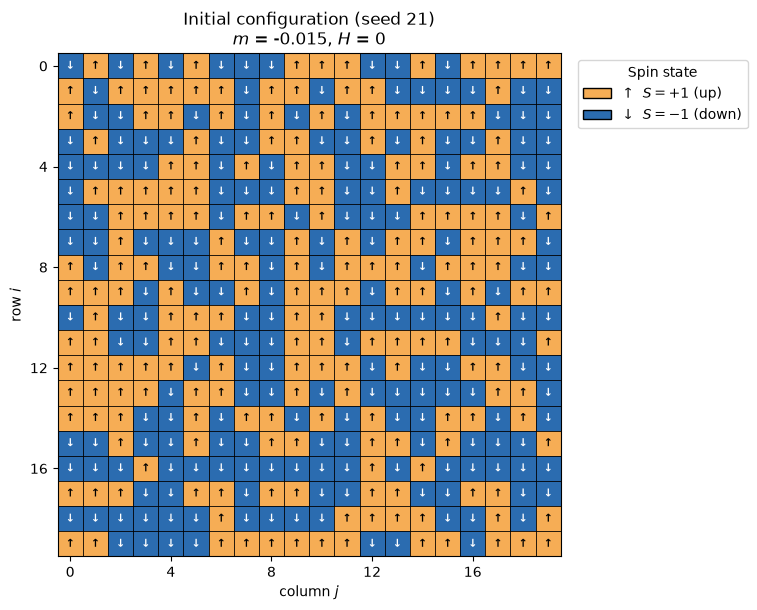

In [12]:
# Parameters (J = kB = 1)
N = 20                          # lattice size 
n_sites = N * N                 # one sweep = N^2 attempted flips
J = 1.0                         # interaction strength
kB = 1.0                        # Boltzmann constant
T_low = 1.0                     # temperature below T_C
T_high = 3.0                    # temperature above T_C 
T_C = 2 / math.log(1 + math.sqrt(2))   # Onsager's exact value, ~2.269
B_ext = 0.5                     # external field 
sweeps_long = 10_000            # Section 2
sweeps_run = 2_500              # Sections 3-5: 2,500 x 400 = 10^6 attempted flips
lattice_seeds = [21, 22, 23, 24]   # seeds of the different initial lattices
os.makedirs("figures", exist_ok=True)


def random_lattice(N, seed):
    # N x N lattice of +1/-1 spins with equal probability
    rng = np.random.default_rng(seed)
    return rng.choice(np.array([-1, 1]), size=(N, N))


def total_energy(S, J=1.0, B=0.0):
    # np.roll wraps the edges (periodic boundaries); down + right neighbors count each bond once
    bonds = S * (np.roll(S, -1, axis=0) + np.roll(S, -1, axis=1))
    return -J * np.sum(bonds) - B * np.sum(S)


def magnetization(S):
    # magnetization per spin, m = M / N^2
    return np.sum(S) / S.size


def plot_spins(S, title, fname):
    # spin map: orange = +1 (up), blue = -1 (down), with grid lines and an arrow per site
    colors = ["#2b6cb0", "#f6ad55"]
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    ax.imshow(S, cmap=plt.matplotlib.colors.ListedColormap(colors), vmin=-1, vmax=1)

    # grid lines on the cell borders (minor ticks at half-integers)
    ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.grid(which="minor", color="black", linewidth=0.6)
    ax.tick_params(which="minor", length=0)

    # up/down arrow in every cell
    for (i, j), s in np.ndenumerate(S):
        ax.text(j, i, "↑" if s > 0 else "↓", ha="center", va="center",
                fontsize=8, fontweight="bold", color="black" if s > 0 else "white")

    ax.set_xticks(range(0, N, 4))
    ax.set_yticks(range(0, N, 4))
    ax.set_xlabel("column $j$")
    ax.set_ylabel("row $i$")
    ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=colors[1], edgecolor="black", label="↑  $S=+1$ (up)"),
                       Patch(facecolor=colors[0], edgecolor="black", label="↓  $S=-1$ (down)")],
              loc="upper left", bbox_to_anchor=(1.02, 1), title="Spin state")
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()


S0 = random_lattice(N, lattice_seeds[0])
print(f"Initial lattice: m = {magnetization(S0):+.3f} (expected 0 +/- 1/N = {1/N:.3f}), H = {total_energy(S0, J):.0f}")
print(f"All spins up:    H = {total_energy(np.ones((N, N)), J):.0f}   (-2JN^2 = {-2*J*n_sites:.0f})")
print(f"All spins down:  H = {total_energy(-np.ones((N, N)), J):.0f}")

plot_spins(S0, f"Initial configuration (seed {lattice_seeds[0]})\n"
               f"$m$ = {magnetization(S0):+.3f}, $H$ = {total_energy(S0, J):.0f}", "figures/fig1_initial.png")

# 2. Implementing the Metropolis Algorithm

`metropolis` does the four steps of the method: pick a random site, flip it, get $\Delta H$, and accept with $P=\min(1,e^{-\Delta H/k_BT})$.

- **Only the local energy change is needed.** Flipping one spin changes only its own bonds, so $\Delta H=2S_{i,j}[J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B]$. This is a few additions instead of re-summing all 400 sites.
- **Lookup tables.** The neighbor sum can only be $-4,-2,0,2,4$ and $S=\pm1$, so there are only 10 possible $\Delta H$ values. `dH_tab` and `P_tab` are built once, so no `exp` is called inside the loop.
- **Fast loop.** The spins are kept in a flat list, the four periodic neighbors of every site are precomputed in `nbrs`, and the random sites and random numbers of a whole sweep are drawn in one call.
- **Running totals.** $H$ and $M$ are updated on every accepted flip ($H\mathrel{+}=\Delta H$, $M\mathrel{-}=2S$) and stored once per sweep, where one sweep is $N^2=400$ attempted flips.
- **Acceptance rate.** The function also counts how many of the attempted flips were accepted. This is the standard health check for a Metropolis run: a very low rate means the lattice is nearly frozen, a very high one means it is just flipping at random.
- **Check.** At the end the running $H$ is compared with `total_energy` using an `assert`, so a bookkeeping mistake would stop the run.

`plot_long` plots $m$ and $H$ against sweeps for one long run, so the 10,000-sweep histories are used and not just the final lattice. The Section 1 lattice is then run for 10,000 sweeps ($4\times10^6$ attempted flips) at $T=1$.

T = 1.0: final m = -1.000, final H = -800, acceptance rate = 0.0012
         averages of last 5,000 sweeps: |m| = 0.9993, H = -798.9


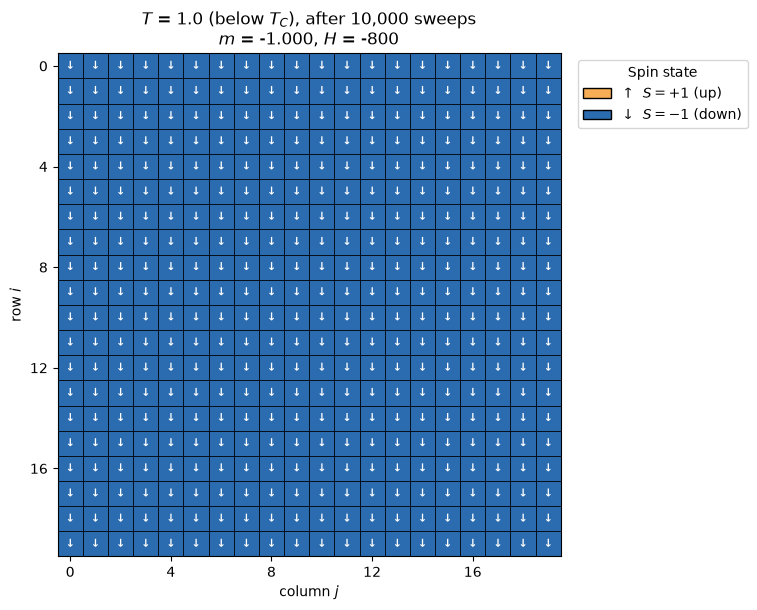

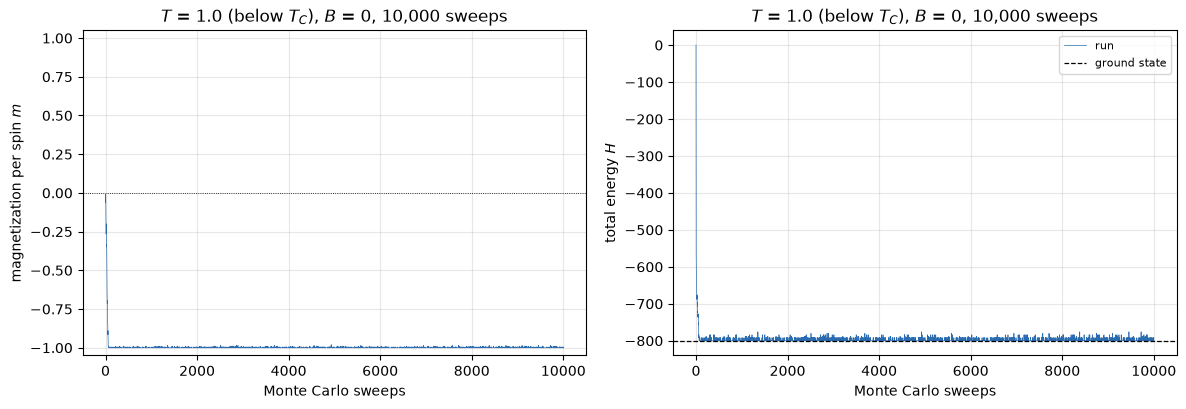

In [13]:
def metropolis(S, T, sweeps, seed, J=1.0, B=0.0, kB=1.0):
    # single-spin-flip Metropolis; returns the final lattice, m and H after every sweep,
    # and the acceptance rate (accepted flips / attempted flips)
    rng = np.random.default_rng(seed)
    N = S.shape[0]
    n = N * N
    spins = S.ravel().tolist()

    # neighbor table (up, down, left, right) of every flat site index, periodic wrap
    idx = np.arange(n).reshape(N, N)
    nbrs = np.stack([np.roll(idx, 1, 0), np.roll(idx, -1, 0),
                     np.roll(idx, 1, 1), np.roll(idx, -1, 1)], axis=-1).reshape(n, 4).tolist()

    # tables indexed [(s+1)//2][nn+4]; nn = neighbor sum in -4..4
    dH_tab = [[2 * s * (J * nn + B) for nn in range(-4, 5)] for s in (-1, 1)]
    P_tab = [[min(1.0, math.exp(-dH / (kB * T))) for dH in row] for row in dH_tab]

    H = total_energy(S, J, B)
    M = int(np.sum(S))
    ms, Hs = np.empty(sweeps + 1), np.empty(sweeps + 1)
    ms[0], Hs[0] = M / n, H
    accepted = 0                                   # running count of accepted flips

    for sweep in range(1, sweeps + 1):
        sites = rng.integers(0, n, n).tolist()     # random sites for one sweep
        us = rng.random(n).tolist()                # uniform numbers for acceptance
        for k, u in zip(sites, us):
            s = spins[k]
            a, b, c, d = nbrs[k]
            col = spins[a] + spins[b] + spins[c] + spins[d] + 4
            row = (s + 1) // 2
            if u < P_tab[row][col]:                # accept with min(1, e^(-dH/kT))
                spins[k] = -s
                H += dH_tab[row][col]
                M -= 2 * s
                accepted += 1
        ms[sweep], Hs[sweep] = M / n, H

    S_final = np.array(spins).reshape(N, N)
    assert math.isclose(H, total_energy(S_final, J, B)), "running energy does not match H"
    return S_final, ms, Hs, accepted / (sweeps * n)


def plot_long(ms, Hs, T, fname):
    # m (left) and H (right) versus sweeps for one long run
    side = "below" if T < T_C else "above"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    ax1.plot(ms, lw=0.5, color="#2b6cb0")
    ax1.axhline(0, color="k", lw=0.6, ls=":")
    ax1.set_ylim(-1.05, 1.05)
    ax1.set_ylabel("magnetization per spin $m$")
    ax2.plot(Hs, lw=0.5, color="#2b6cb0", label="run")
    ax2.axhline(-2 * J * n_sites, color="k", lw=0.9, ls="--", label="ground state")
    ax2.set_ylabel("total energy $H$")
    ax2.legend(fontsize=8, loc="best")
    for ax in (ax1, ax2):
        ax.set_xlabel("Monte Carlo sweeps")
        ax.set_title(f"$T$ = {T} ({side} $T_C$), $B$ = 0, {len(ms) - 1:,} sweeps")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()


#10,000 sweeps (4 x 10^6 attempted flips) at T = 1
S_low, ms_low, Hs_low, acc_low = metropolis(S0, T_low, sweeps_long, seed=100, J=J, B=0.0, kB=kB)
print(f"T = {T_low}: final m = {ms_low[-1]:+.3f}, final H = {Hs_low[-1]:.0f}, acceptance rate = {acc_low:.4f}")
print(f"         averages of last 5,000 sweeps: |m| = {np.abs(ms_low[-5000:]).mean():.4f}, H = {Hs_low[-5000:].mean():.1f}")

plot_spins(S_low, f"$T$ = {T_low} (below $T_C$), after {sweeps_long:,} sweeps\n"
                  f"$m$ = {ms_low[-1]:+.3f}, $H$ = {Hs_low[-1]:.0f}", "figures/fig2_final_low.png")
plot_long(ms_low, Hs_low, T_low, "figures/fig3_long_low.png")

# 3. Investigating Spontaneous Magnetization

- `run_set` runs the four initial lattices (seeds 21 to 24) for 2,500 sweeps each. That is $2{,}500\times400=10^6$ attempted flips, the upper end of the range given in the problem.
- Each run uses a flip seed different from its lattice seed, so the starting lattice and the random flips are independent.
- $m$ and $H$ are recorded after every sweep, and `plot_mE` plots them against the sweep number.
- Averages use the last 1,000 sweeps, which is well after every run has settled.
- **Error bars.** Consecutive sweeps are not independent samples, because one sweep only changes a few spins. Using $s/\sqrt{n}$ on 1,000 correlated sweeps would give an error bar several times too small. `block_error` instead splits the data into 10 blocks of 100 sweeps, averages each block, and takes the standard error of those 10 block averages. The blocks are long enough that their averages are nearly independent, so this is a fair estimate.

T = 1.0, B = 0.0, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = -0.9992 +/- 0.00011, <H> =  -798.8 +/- 0.2, acceptance = 0.0023
T = 1.0, B = 0.0, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = -0.9993 +/- 0.00009, <H> =  -798.9 +/- 0.1, acceptance = 0.0023
T = 1.0, B = 0.0, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.9994 +/- 0.00010, <H> =  -799.0 +/- 0.2, acceptance = 0.0250
T = 1.0, B = 0.0, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = +0.9994 +/- 0.00011, <H> =  -799.0 +/- 0.2, acceptance = 0.0027


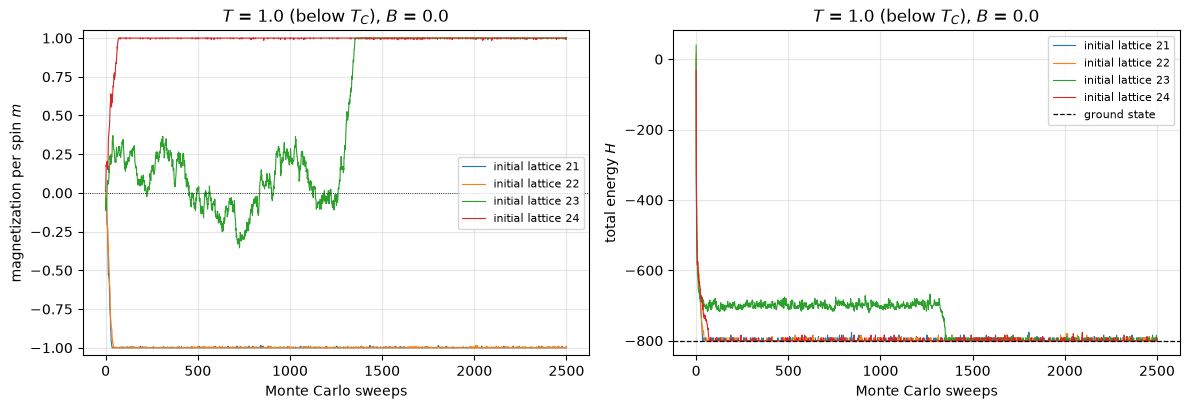

In [14]:
n_avg = 1_000     # sweeps used for the equilibrium averages
n_blocks = 10     # blocks used for the error bars


def block_error(x, n_blocks=n_blocks):
    # Error bar of the mean of CORRELATED samples. Consecutive sweeps are not
    # independent, so s/sqrt(n) is too small. Splitting the data into blocks and
    # taking the standard error of the block averages removes most of that bias.
    x = np.asarray(x)
    b = len(x) // n_blocks
    block_means = x[:b * n_blocks].reshape(n_blocks, b).mean(axis=1)
    return block_means.std(ddof=1) / np.sqrt(n_blocks)


def run_set(T, B):
    # runs every initial lattice in lattice_seeds at temperature T and field B
    runs = []
    for s in lattice_seeds:
        _, ms, Hs, acc = metropolis(random_lattice(N, s), T, sweeps_run, seed=s + 1000, J=J, B=B, kB=kB)
        runs.append((ms, Hs, acc))
        m_eq, H_eq = ms[-n_avg:], Hs[-n_avg:]      # equilibrium part of the run
        print(f"T = {T}, B = {B}, lattice {s}: start m = {ms[0]:+.3f} | last {n_avg} sweeps: "
              f"<m> = {m_eq.mean():+.4f} +/- {block_error(m_eq):.5f}, "
              f"<H> = {H_eq.mean():7.1f} +/- {block_error(H_eq):.1f}, acceptance = {acc:.4f}")
    return runs


def plot_mE(runs, T, B, fname):
    # m (left) and H (right) versus sweeps for every initial lattice
    side = "below" if T < T_C else "above"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    for s, (ms, Hs, _) in zip(lattice_seeds, runs):
        ax1.plot(ms, lw=0.8, label=f"initial lattice {s}")
        ax2.plot(Hs, lw=0.8, label=f"initial lattice {s}")
    ax1.axhline(0, color="k", lw=0.6, ls=":")
    ax2.axhline(-2 * J * n_sites - B * n_sites, color="k", lw=0.9, ls="--", label="ground state")
    ax1.set_ylim(-1.05, 1.05)
    ax1.set_ylabel("magnetization per spin $m$")
    ax2.set_ylabel("total energy $H$")
    for ax in (ax1, ax2):
        ax.set_xlabel("Monte Carlo sweeps")
        ax.set_title(f"$T$ = {T} ({side} $T_C$), $B$ = {B}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="best")
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()


# four different initial lattices at T = 1, no field
runs_low = run_set(T_low, 0.0)
plot_mE(runs_low, T_low, 0.0, "figures/fig4_mE_low.png")

# 4. Introducing an External Magnetic Field

The same four lattices are run again with $B=0.5$. Nothing else changes, because the field is already built into both functions: `total_energy` has the $-B\sum S_{i,j}$ term, and `metropolis` has $B$ inside the $\Delta H$ table. The ground-state line in the energy plot moves to $-2JN^2-BN^2=-1000$.

T = 1.0, B = 0.5, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = +0.9997 +/- 0.00003, <H> =  -999.5 +/- 0.1, acceptance = 0.0008
T = 1.0, B = 0.5, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = +0.9997 +/- 0.00005, <H> =  -999.5 +/- 0.1, acceptance = 0.0006
T = 1.0, B = 0.5, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.9998 +/- 0.00004, <H> =  -999.7 +/- 0.1, acceptance = 0.0006
T = 1.0, B = 0.5, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = +0.9998 +/- 0.00006, <H> =  -999.6 +/- 0.1, acceptance = 0.0006


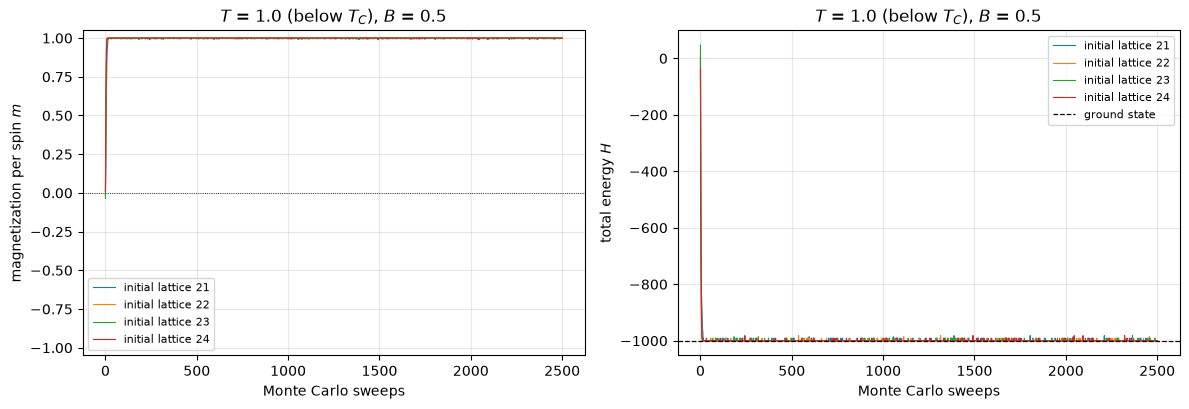

In [15]:
# same four initial lattices at T = 1, with B = 0.5
runs_B_low = run_set(T_low, B_ext)
plot_mE(runs_B_low, T_low, B_ext, "figures/fig5_mE_B_low.png")

# 5. Critical Temperature

Sections 2, 3 and 4 are repeated at $T=3.0$, which is above $T_C=2/\ln(1+\sqrt2)\approx2.269$. The same initial lattices and the same flip seeds are used, so the only difference from the runs above is the temperature. The cells below redo Section 2 (one long run), Section 3 ($B=0$) and Section 4 ($B=0.5$), and the last cell collects all four cases in one table and checks them against the exact result.

T = 3.0: final m = +0.045, final H = -312, acceptance rate = 0.4609
         averages of last 5,000 sweeps: |m| = 0.1444, H = -327.5


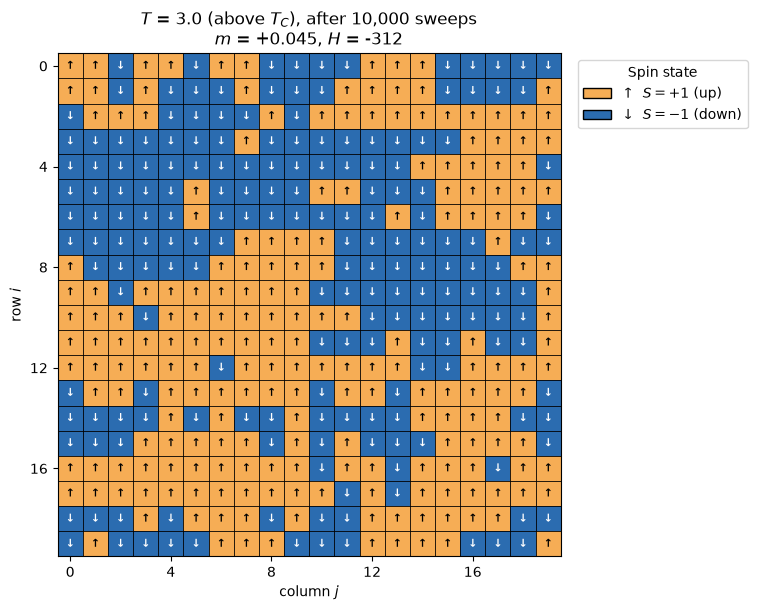

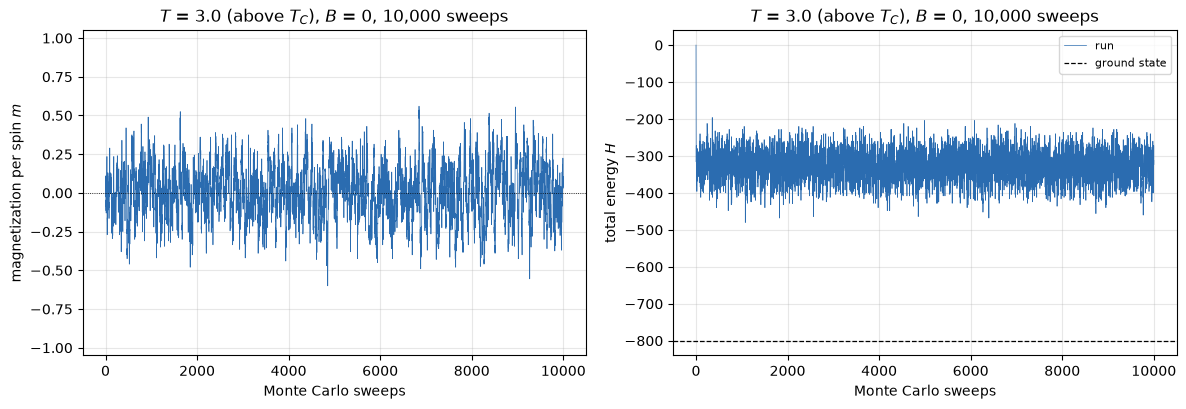

In [16]:
# Section 2 at T = 3.0: same initial lattice, 10,000 sweeps
S_high, ms_high, Hs_high, acc_high = metropolis(S0, T_high, sweeps_long, seed=100, J=J, B=0.0, kB=kB)
print(f"T = {T_high}: final m = {ms_high[-1]:+.3f}, final H = {Hs_high[-1]:.0f}, acceptance rate = {acc_high:.4f}")
print(f"         averages of last 5,000 sweeps: |m| = {np.abs(ms_high[-5000:]).mean():.4f}, H = {Hs_high[-5000:].mean():.1f}")
plot_spins(S_high, f"$T$ = {T_high} (above $T_C$), after {sweeps_long:,} sweeps\n"
                   f"$m$ = {ms_high[-1]:+.3f}, $H$ = {Hs_high[-1]:.0f}", "figures/fig2_final_high.png")
plot_long(ms_high, Hs_high, T_high, "figures/fig3_long_high.png")

**Section 3 repeated at $T=3.0$ ($B=0$).** Same four initial lattices as the $T=1$ runs.

T = 3.0, B = 0.0, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = -0.0393 +/- 0.02683, <H> =  -330.0 +/- 1.5, acceptance = 0.4591
T = 3.0, B = 0.0, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = +0.0496 +/- 0.01338, <H> =  -329.6 +/- 1.7, acceptance = 0.4599
T = 3.0, B = 0.0, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.0171 +/- 0.02403, <H> =  -326.8 +/- 2.8, acceptance = 0.4608
T = 3.0, B = 0.0, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = -0.0165 +/- 0.03163, <H> =  -325.5 +/- 2.7, acceptance = 0.4616


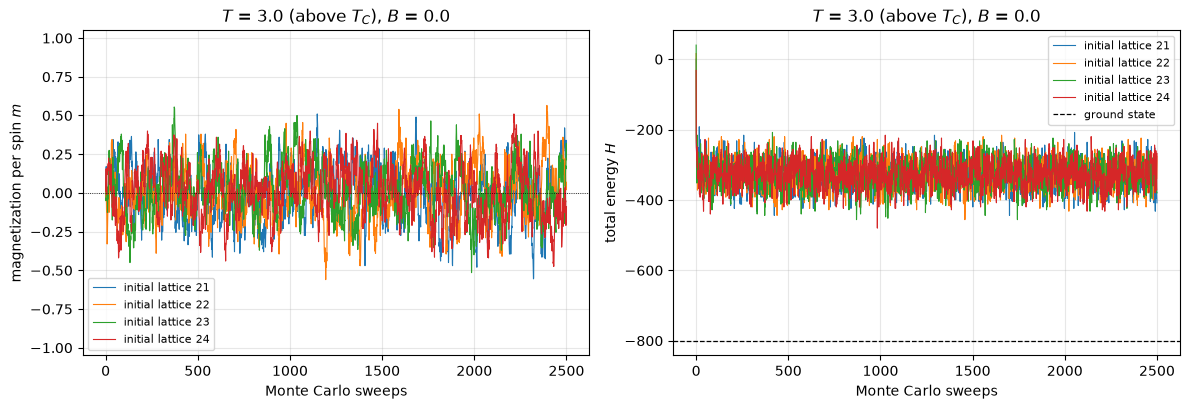

In [17]:
# Section 3 at T = 3.0: no field
runs_high = run_set(T_high, 0.0)
plot_mE(runs_high, T_high, 0.0, "figures/fig4_mE_high.png")

**Section 4 repeated at $T=3.0$ ($B=0.5$).** Same lattices again, with the field turned on.

T = 3.0, B = 0.5, lattice 21: start m = -0.015 | last 1000 sweeps: <m> = +0.7713 +/- 0.00326, <H> =  -699.2 +/- 3.3, acceptance = 0.2116
T = 3.0, B = 0.5, lattice 22: start m = +0.010 | last 1000 sweeps: <m> = +0.7636 +/- 0.00537, <H> =  -691.4 +/- 5.3, acceptance = 0.2139
T = 3.0, B = 0.5, lattice 23: start m = -0.035 | last 1000 sweeps: <m> = +0.7688 +/- 0.00418, <H> =  -698.1 +/- 4.1, acceptance = 0.2123
T = 3.0, B = 0.5, lattice 24: start m = +0.010 | last 1000 sweeps: <m> = +0.7715 +/- 0.00464, <H> =  -699.6 +/- 4.0, acceptance = 0.2117


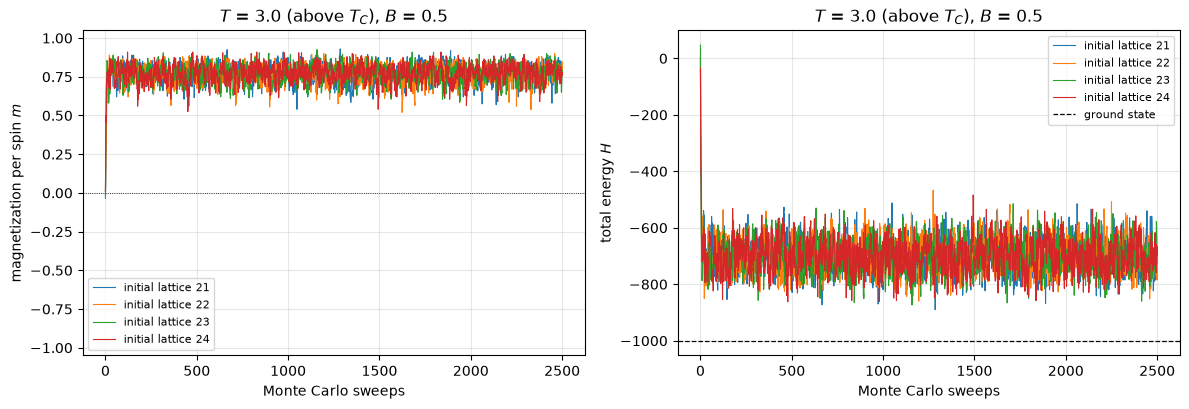

In [18]:
# Section 4 at T = 3.0: with B = 0.5
runs_B_high = run_set(T_high, B_ext)
plot_mE(runs_B_high, T_high, B_ext, "figures/fig5_mE_B_high.png")

**Summary table and checking.**

- The table pools the four lattices for each case. Since the four runs are independent, the pooled error bar is the standard error of the four run averages.
- $\langle|m|\rangle$ is listed next to $\langle m\rangle$ because the two signs cancel in $\langle m\rangle$ when there is no field, which is why that one entry has a very large error bar.
- `onsager_m` is the exact spontaneous magnetization of the infinite 2D lattice at $B=0$, $m=\left[1-\sinh^{-4}(2J/k_BT)\right]^{1/8}$ below $T_C$ and $0$ above it. Comparing the simulated $\langle|m|\rangle$ with it is a direct check that the algorithm is sampling the Boltzmann distribution correctly.

In [19]:
def onsager_m(T, J=1.0, kB=1.0):
    # exact spontaneous magnetization per spin of the INFINITE 2D lattice at B = 0
    if T >= T_C:
        return 0.0
    return (1 - math.sinh(2 * J / (kB * T)) ** -4) ** 0.125


def run_error(v):
    # the four lattices are independent runs, so the error of their average is
    # the standard error of the four run averages
    return v.std(ddof=1) / np.sqrt(len(v))


cases = [(T_low, 0.0, runs_low), (T_high, 0.0, runs_high),
         (T_low, B_ext, runs_B_low), (T_high, B_ext, runs_B_high)]

print(f"Averages over the last {n_avg} sweeps of each run, pooled over the {len(lattice_seeds)} lattices")
print(f"{'T':>5} {'B':>5} {'<|m|>':>19} {'<m>':>19} {'<H>':>18} {'<H>/N^2':>9} {'accept':>7}")
for T, B, runs in cases:
    abs_m = np.array([np.abs(ms[-n_avg:]).mean() for ms, _, _ in runs])   # |m| of each run
    sig_m = np.array([ms[-n_avg:].mean() for ms, _, _ in runs])           # signed m of each run
    H_run = np.array([Hs[-n_avg:].mean() for _, Hs, _ in runs])
    acc = np.mean([a for _, _, a in runs])
    print(f"{T:5.1f} {B:5.1f} {abs_m.mean():8.5f} +/-{run_error(abs_m):8.5f} "
          f"{sig_m.mean():+8.4f} +/-{run_error(sig_m):8.5f} "
          f"{H_run.mean():9.1f} +/-{run_error(H_run):6.1f} "
          f"{H_run.mean()/n_sites:9.3f} {acc:7.4f}")

# Check against the exact result (Onsager) for B = 0
print(f"\nExact check at B = 0, T_C = {T_C:.4f}")
for T, runs in ((T_low, runs_low), (T_high, runs_high)):
    abs_m = np.array([np.abs(ms[-n_avg:]).mean() for ms, _, _ in runs])
    print(f"  T = {T}: simulated <|m|> = {abs_m.mean():.5f} +/- {run_error(abs_m):.5f}, "
          f"exact m = {onsager_m(T):.5f}")
print("  (above T_C the exact value is 0; the simulated <|m|> stays positive because m")
print("   fluctuates around 0 on a finite 20x20 lattice and |m| cannot be negative)")

Averages over the last 1000 sweeps of each run, pooled over the 4 lattices
    T     B               <|m|>                 <m>                <H>   <H>/N^2  accept
  1.0   0.0  0.99931 +/- 0.00003  +0.0001 +/- 0.57695    -798.9 +/-   0.0    -1.997  0.0081
  3.0   0.0  0.14036 +/- 0.00313  +0.0027 +/- 0.01945    -327.9 +/-   1.1    -0.820  0.4603
  1.0   0.5  0.99976 +/- 0.00002  +0.9998 +/- 0.00002    -999.6 +/-   0.0    -2.499  0.0007
  3.0   0.5  0.76880 +/- 0.00184  +0.7688 +/- 0.00184    -697.1 +/-   1.9    -1.743  0.2124

Exact check at B = 0, T_C = 2.2692
  T = 1.0: simulated <|m|> = 0.99931 +/- 0.00003, exact m = 0.99928
  T = 3.0: simulated <|m|> = 0.14036 +/- 0.00313, exact m = 0.00000
  (above T_C the exact value is 0; the simulated <|m|> stays positive because m
   fluctuates around 0 on a finite 20x20 lattice and |m| cannot be negative)


### Problem code summary

Include a brief summary (2-3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* This script simulates the 2D Ising model on a $20\times20$ periodic lattice with the single-spin-flip Metropolis algorithm, below ($T=1$) and above ($T=3$) the critical temperature and with and without a field $B=0.5$, recording $m$, $H$ and the acceptance rate for every run. Since flipping one spin only changes its own four bonds, I used the local $\Delta H=2S_{i,j}[J(\text{neighbor sum})+B]$ instead of re-summing the lattice, and because that expression has only ten possible values I precomputed $\Delta H$ and its acceptance probability in lookup tables, kept the spins and their periodic neighbors in flat lists, and updated $H$ and $M$ from each accepted flip, which keeps a 4-million-flip run to about a second. The field and the seeds are built into the functions so for Sections 4 and 5 I just called them with a different $B$ or $T$, and the results are checked rather than only reported: an `assert` on the running energy, error bars from blocking within a run and from the spread of the four independent runs, and a comparison of $\langle|m|\rangle$ with Onsager's exact value.